Original song (Kesariya): 30.00 seconds loaded
Karaoke version (Kesariya): 30.00 seconds loaded
Different song (Believer): 29.86 seconds loaded

CORRELATION RESULTS
                                             Track pair  Pearson correlation  Peak normalized cross-correlation  Peak lag (seconds)
 Original song (Kesariya) vs Karaoke version (Kesariya)              -0.0123                             0.0522             -1.3052
  Original song (Kesariya) vs Different song (Believer)              -0.0020                             0.0270            -10.2029
Karaoke version (Kesariya) vs Different song (Believer)               0.0032                             0.0128              2.2774

Results saved to correlation_results.csv


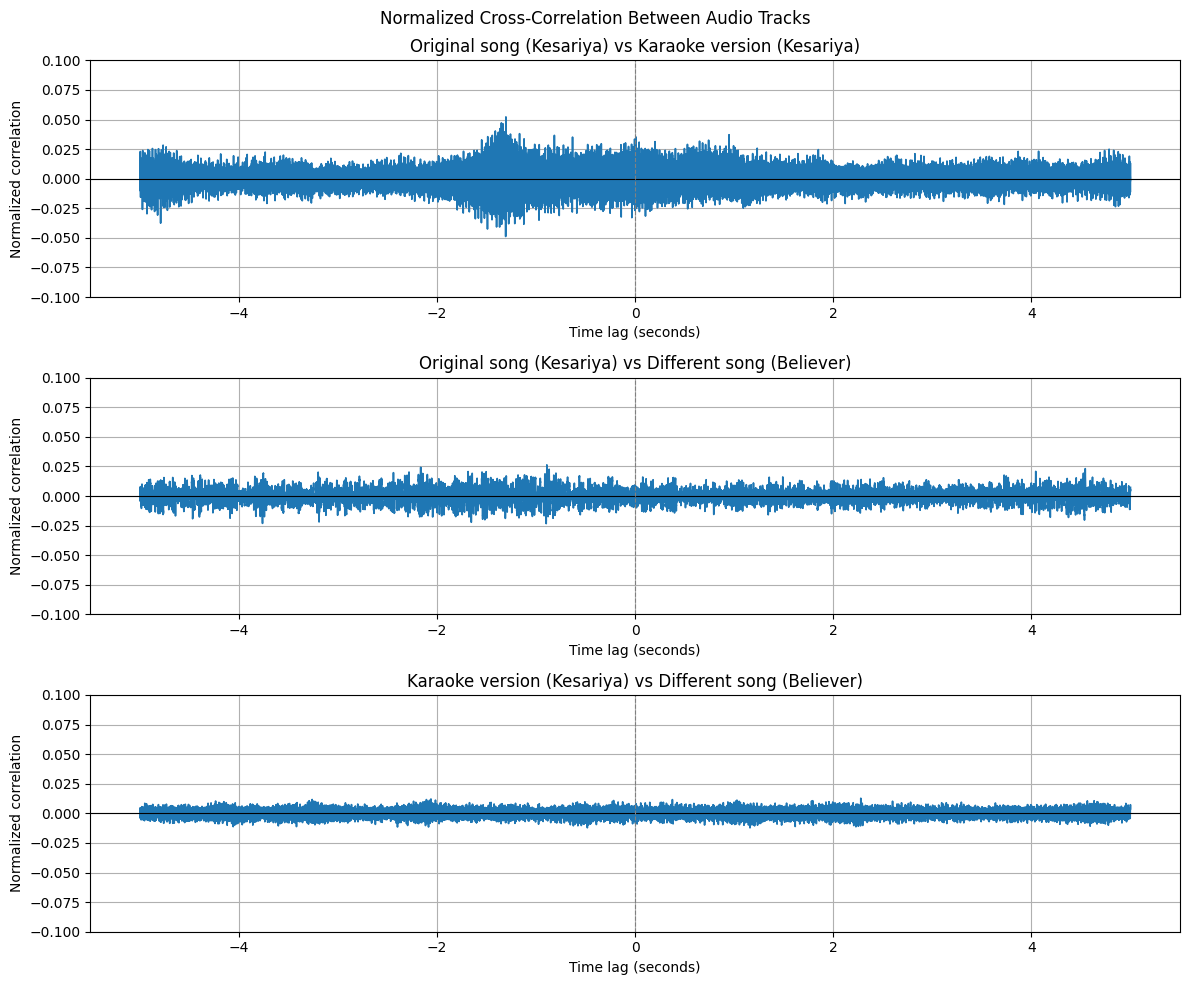

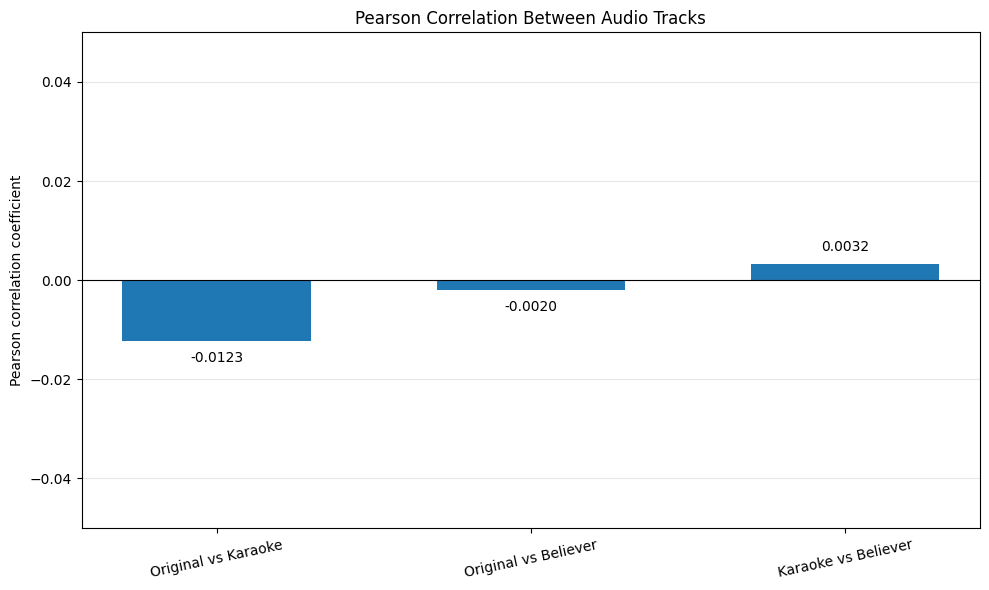


Both correlation plots have been saved successfully.


In [ ]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
from scipy.signal import correlate, correlation_lags
from scipy.stats import pearsonr

# --------------------------------------------------
# 1. Load the three audio files
# --------------------------------------------------

files = {
    "Original song (Kesariya)": "kesariya.mp3",
    "Karaoke version (Kesariya)": "kesariya_instrumental.mp3",
    "Different song (Believer)": "believer.mp3"
}

SAMPLE_RATE = 8000
DURATION = 30

signals = {}

for name, filename in files.items():
    if not os.path.exists(filename):
        raise FileNotFoundError(
            f"File not found: {filename}\n"
            "Problem to load audio files"
        )

    audio, sr = librosa.load(
        filename,
        sr=SAMPLE_RATE,
        mono=True,
        duration=DURATION
    )

    if len(audio) == 0:
        raise ValueError(f"No audio data could be loaded from {filename}")

    # Remove DC offset and normalize amplitude
    audio = audio - np.mean(audio)
    peak = np.max(np.abs(audio))

    if peak > 0:
        audio = audio / peak

    signals[name] = audio
    print(f"{name}: {len(audio) / SAMPLE_RATE:.2f} seconds loaded")


# --------------------------------------------------
# 2. Calculate correlations for all three pairs
# --------------------------------------------------

pairs = [
    ("Original song (Kesariya)", "Karaoke version (Kesariya)"),
    ("Original song (Kesariya)", "Different song (Believer)"),
    ("Karaoke version (Kesariya)", "Different song (Believer)")
]

results = []
cross_corr_data = {}

for name1, name2 in pairs:
    x = signals[name1]
    y = signals[name2]

    # Pearson correlation between samples aligned at the start
    n = min(len(x), len(y))
    pearson_value = pearsonr(x[:n], y[:n]).statistic

    # Calculate full cross-correlation
    xcorr = correlate(x, y, mode="full", method="fft")
    lags = correlation_lags(len(x), len(y), mode="full")

    # Normalize cross-correlation by signal energies
    denominator = np.sqrt(np.sum(x**2) * np.sum(y**2))

    if denominator > 0:
        normalized_xcorr = xcorr / denominator
    else:
        normalized_xcorr = np.zeros_like(xcorr)

    # Find the strongest match by absolute magnitude
    peak_index = np.argmax(np.abs(normalized_xcorr))
    peak_corr = normalized_xcorr[peak_index]
    peak_lag_seconds = lags[peak_index] / SAMPLE_RATE

    cross_corr_data[(name1, name2)] = (
        lags / SAMPLE_RATE,
        normalized_xcorr
    )

    results.append({
        "Track pair": f"{name1} vs {name2}",
        "Pearson correlation": pearson_value,
        "Peak normalized cross-correlation": peak_corr,
        "Peak lag (seconds)": peak_lag_seconds
    })


# --------------------------------------------------
# 3. Print and save the results
# --------------------------------------------------

df = pd.DataFrame(results)

print("\nCORRELATION RESULTS")
print(df.round(4).to_string(index=False))

df.to_csv("correlation_results.csv", index=False)
print("\nResults saved to correlation_results.csv")


# --------------------------------------------------
# 4. Plot normalized cross-correlation
# --------------------------------------------------

fig, axes = plt.subplots(3, 1, figsize=(12, 10))

for ax, pair in zip(axes, pairs):
    lags_seconds, values = cross_corr_data[pair]

    # Display lags from -5 to +5 seconds
    mask = (lags_seconds >= -5) & (lags_seconds <= 5)
    shown_lags = lags_seconds[mask]
    shown_values = values[mask]

    ax.plot(shown_lags, shown_values, linewidth=1.2)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)

    # Zoom the vertical axis to make small values visible
    ax.set_ylim(-0.1, 0.1)

    ax.set_title(f"{pair[0]} vs {pair[1]}")
    ax.set_xlabel("Time lag (seconds)")
    ax.set_ylabel("Normalized correlation")
    ax.grid(True)

plt.suptitle("Normalized Cross-Correlation Between Audio Tracks")
plt.tight_layout()
plt.savefig("cross_correlation_plots.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()


# --------------------------------------------------
# 5. Plot Pearson correlation
# --------------------------------------------------

labels = [
    "Original vs Karaoke",
    "Original vs Believer",
    "Karaoke vs Believer"
]

pearson_values = df["Pearson correlation"].values

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(labels, pearson_values, width=0.6)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylim(-0.05, 0.05)
ax.set_ylabel("Pearson correlation coefficient")
ax.set_title("Pearson Correlation Between Audio Tracks")
ax.tick_params(axis="x", labelrotation=12)
ax.grid(axis="y", alpha=0.3)

# Label each bar with its actual correlation value
for bar, value in zip(bars, pearson_values):
    if value >= 0:
        y_position = value + 0.002
        vertical_alignment = "bottom"
    else:
        y_position = value - 0.002
        vertical_alignment = "top"

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        y_position,
        f"{value:.4f}",
        ha="center",
        va=vertical_alignment
    )

plt.tight_layout()
plt.savefig("pearson_correlation_plot.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()
